# 📊 Exploratory Data Analysis: OUC-CGE Video Engagement Dataset

**Open University Classroom Group Engagement (OUC-CGE)**

This notebook performs a comprehensive, research-grade exploratory data analysis (EDA) on the OUC-CGE video dataset, which categorises classroom video clips into three engagement levels: **High**, **Medium**, and **Low**.

---

**Notebook Sections:**

| # | Section | Purpose |
|---|---------|--------|
| 1 | Setup & Imports | Environment configuration |
| 2 | Dataset Loading | Scanning, cataloguing, and building metadata |
| 3 | Class Distribution | Balance analysis |
| 4 | Video Metadata Extraction | Resolution, FPS, duration, file size |
| 5 | Duration Analysis | Temporal statistics |
| 6 | Frame Count Analysis | Per-class frame statistics |
| 7 | Resolution Analysis | Spatial resolution distribution |
| 8 | FPS Analysis | Frame-rate distribution |
| 9 | File Size Analysis | Storage distribution |
| 10 | Visual Sample Inspection | Frame grids per class |
| 11 | Frame-Level Analysis | Brightness / contrast / intensity |
| 12 | Motion Analysis | Inter-frame motion estimation |
| 13 | Face Detection (Advanced) | Haar-cascade face statistics |
| 14 | Dataset Quality Checks | Corrupted / unreadable files |
| 15 | Research-Oriented Summary | Key EDA findings |
| 16 | Export Results | CSVs and publication-ready figures |

---

**Author:** *[Your Name]*  
**Date:** *Auto-generated*  
**Dataset:** OUC-CGE (Open University Classroom Group Engagement)

---
## 1. Setup and Imports

In [1]:
# ── Install dependencies (uncomment if needed) ──────────────────────────────
# !pip install numpy pandas matplotlib seaborn opencv-python tqdm plotly kaleido

# ── Standard library ────────────────────────────────────────────────────────
import os
import warnings
import random
from pathlib import Path
from collections import Counter

# ── Data & numerics ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ── Computer vision ─────────────────────────────────────────────────────────
import cv2

# ── Progress bars ───────────────────────────────────────────────────────────
from tqdm.notebook import tqdm

# ── Reproducibility ─────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Plot styling ────────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.2)
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.family': 'sans-serif',
})

# ── Color palette for engagement classes ────────────────────────────────────
CLASS_COLORS = {'High': '#2ecc71', 'Medium': '#f39c12', 'Low': '#e74c3c'}
CLASS_ORDER  = ['High', 'Medium', 'Low']

print('✅ All libraries imported successfully.')
print(f'   OpenCV version : {cv2.__version__}')
print(f'   NumPy version  : {np.__version__}')
print(f'   Pandas version : {pd.__version__}')

✅ All libraries imported successfully.
   OpenCV version : 4.12.0
   NumPy version  : 1.26.0
   Pandas version : 2.2.2


---
## 2. Dataset Loading

The OUC-CGE dataset is organised as:
```
OUC-CGE/
├── high/
│   ├── high-2636（1-1000）/high-2636（1-1000）/  → view*.mp4
│   ├── high-2636(2001-2190)/high-2636(2001-2190)/  → view*.mp4
│   └── ...
├── mid/
│   └── ...
└── low/
    └── ...
```
We recursively scan for `.mp4` files and assign class labels.

In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURABLE: Set your dataset root path here
# ═══════════════════════════════════════════════════════════════════════════
DATASET_PATH = Path(r'E:\Video_Engagement\OUC-CGE')

# Output directory for saved results
OUTPUT_DIR = Path(r'E:\Video_Engagement\eda_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ═══════════════════════════════════════════════════════════════════════════
# Class mapping:  folder-name → label
# ═══════════════════════════════════════════════════════════════════════════
FOLDER_TO_CLASS = {
    'high': 'High',
    'mid':  'Medium',
    'low':  'Low',
}
CLASS_TO_ID = {'High': 0, 'Medium': 1, 'Low': 2}

print(f'📁 Dataset root : {DATASET_PATH}')
print(f'📂 Output dir   : {OUTPUT_DIR}')
assert DATASET_PATH.exists(), f'Dataset path does not exist: {DATASET_PATH}'

📁 Dataset root : E:\Video_Engagement\OUC-CGE
📂 Output dir   : E:\Video_Engagement\eda_results


In [3]:
def scan_dataset(root: Path) -> pd.DataFrame:
    """
    Recursively scan the OUC-CGE dataset tree and build a catalogue DataFrame.
    
    Returns
    -------
    pd.DataFrame with columns:
        video_path   – absolute path to the .mp4 file
        filename     – basename of the video file
        class_label  – High / Medium / Low
        class_id     – 0 / 1 / 2
    """
    records = []
    for class_folder, class_label in FOLDER_TO_CLASS.items():
        class_dir = root / class_folder
        if not class_dir.exists():
            print(f'⚠️  Class folder not found: {class_dir}')
            continue
        # Walk recursively through all sub-directories
        for video_path in sorted(class_dir.rglob('*.mp4')):
            records.append({
                'video_path':  str(video_path),
                'filename':    video_path.name,
                'class_label': class_label,
                'class_id':    CLASS_TO_ID[class_label],
            })
    df = pd.DataFrame(records)
    return df

# ── Build the catalogue ─────────────────────────────────────────────────────
df_catalogue = scan_dataset(DATASET_PATH)

print(f'\n📹 Total videos discovered: {len(df_catalogue):,}')
print(f'\n── Videos per class ──')
print(df_catalogue['class_label'].value_counts().to_string())
print(f'\n── Dataset summary ──')
df_catalogue.head(10)


📹 Total videos discovered: 7,439

── Videos per class ──
class_label
Low       3041
High      2345
Medium    2053

── Dataset summary ──


,video_path,filename,class_label,class_id
0,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view1.mp4,High,0
1,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view10.mp4,High,0
2,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view11.mp4,High,0
3,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view12.mp4,High,0
4,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view2.mp4,High,0
5,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view3.mp4,High,0
6,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view4.mp4,High,0
7,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view5.mp4,High,0
8,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view6.mp4,High,0
9,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view7.mp4,High,0


In [4]:
# ── Summary statistics table ────────────────────────────────────────────────
summary = (
    df_catalogue.groupby('class_label')
    .agg(count=('filename', 'count'))
    .reindex(CLASS_ORDER)
)
summary['percentage'] = (summary['count'] / summary['count'].sum() * 100).round(2)
summary.loc['TOTAL'] = [summary['count'].sum(), 100.0]
summary['count'] = summary['count'].astype(int)

print('\n════════════════════════════════════════════')
print('       OUC-CGE Dataset Summary')
print('════════════════════════════════════════════')
display(summary)


════════════════════════════════════════════
       OUC-CGE Dataset Summary
════════════════════════════════════════════


,count,percentage
class_label,,
High,2345,31.52
Medium,2053,27.60
Low,3041,40.88
TOTAL,7439,100.00


---
## 3. Class Distribution Analysis

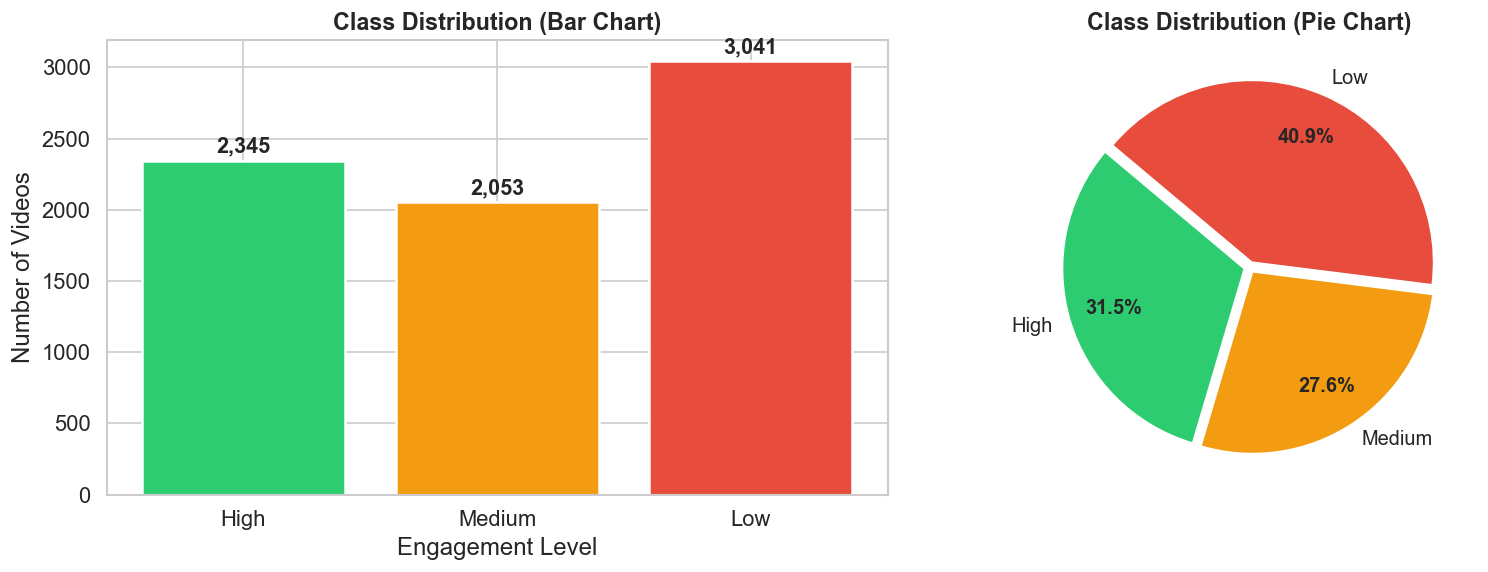

💾 Saved → E:\Video_Engagement\eda_results\class_distribution.png


In [5]:
class_counts = df_catalogue['class_label'].value_counts().reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Bar chart ───────────────────────────────────────────────────────────────
ax = axes[0]
bars = ax.bar(class_counts.index, class_counts.values,
              color=[CLASS_COLORS[c] for c in class_counts.index],
              edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f'{val:,}', ha='center', va='bottom', fontweight='bold', fontsize=13)
ax.set_title('Class Distribution (Bar Chart)', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Videos')
ax.set_xlabel('Engagement Level')

# ── Pie chart ───────────────────────────────────────────────────────────────
ax = axes[1]
wedges, texts, autotexts = ax.pie(
    class_counts.values,
    labels=class_counts.index,
    colors=[CLASS_COLORS[c] for c in class_counts.index],
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.75,
    explode=[0.03] * len(class_counts),
    textprops={'fontsize': 12},
)
for t in autotexts:
    t.set_fontweight('bold')
ax.set_title('Class Distribution (Pie Chart)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "class_distribution.png"}')

In [6]:
# ── Class imbalance analysis ────────────────────────────────────────────────
max_class = class_counts.max()
min_class = class_counts.min()
imbalance_ratio = max_class / min_class

print('═══════════════════════════════════════════════════════')
print('  Class Imbalance Analysis')
print('═══════════════════════════════════════════════════════')
for cls in CLASS_ORDER:
    count = class_counts[cls]
    pct = count / class_counts.sum() * 100
    print(f'  {cls:8s}: {count:>5,} videos  ({pct:5.1f}%)')
print(f'\n  Imbalance ratio (max/min): {imbalance_ratio:.2f}')
print('───────────────────────────────────────────────────────')
if imbalance_ratio < 1.5:
    print('  ✅ Dataset is approximately BALANCED.')
    print('     Standard training procedures should work well.')
elif imbalance_ratio < 3.0:
    print('  ⚠️  Dataset has MODERATE imbalance.')
    print('     Consider: class-weighted loss, oversampling (SMOTE),') 
    print('     or stratified splitting during train/val/test creation.')
else:
    print('  🚨 Dataset is HIGHLY IMBALANCED.')
    print('     Strongly recommend: focal loss, class-balanced sampling,')
    print('     data augmentation, or undersampling majority classes.')
print('═══════════════════════════════════════════════════════')

═══════════════════════════════════════════════════════
  Class Imbalance Analysis
═══════════════════════════════════════════════════════
  High    : 2,345 videos  ( 31.5%)
  Medium  : 2,053 videos  ( 27.6%)
  Low     : 3,041 videos  ( 40.9%)

  Imbalance ratio (max/min): 1.48
───────────────────────────────────────────────────────
  ✅ Dataset is approximately BALANCED.
     Standard training procedures should work well.
═══════════════════════════════════════════════════════


---
## 4. Video Metadata Extraction

For every video in the dataset, we extract:
- **Width × Height** (resolution)
- **FPS** (frames per second)
- **Total frames**
- **Duration** (seconds)
- **File size** (MB)

> ⏱️ This cell processes all videos. It may take several minutes depending on dataset size.

In [7]:
def extract_video_metadata(video_path: str) -> dict:
    """
    Extract metadata from a single video file using OpenCV.
    
    Returns a dict with width, height, fps, total_frames, duration_sec, 
    file_size_mb, and a corrupted flag.
    """
    result = {
        'width': None,
        'height': None,
        'fps': None,
        'total_frames': None,
        'duration_sec': None,
        'file_size_mb': None,
        'resolution': None,
        'is_corrupted': False,
    }
    
    # File size
    try:
        result['file_size_mb'] = round(os.path.getsize(video_path) / (1024 * 1024), 3)
    except OSError:
        result['is_corrupted'] = True
        return result
    
    # OpenCV metadata
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        result['is_corrupted'] = True
        return result
    
    try:
        result['width']        = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        result['height']       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        result['fps']          = round(cap.get(cv2.CAP_PROP_FPS), 2)
        result['total_frames'] = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        if result['fps'] and result['fps'] > 0:
            result['duration_sec'] = round(result['total_frames'] / result['fps'], 3)
        
        result['resolution'] = f"{result['width']}x{result['height']}"
        
        # Quick corruption check: try to read the first frame
        ret, frame = cap.read()
        if not ret or frame is None:
            result['is_corrupted'] = True
    except Exception:
        result['is_corrupted'] = True
    finally:
        cap.release()
    
    return result

print('🔄 Extracting metadata from all videos...')
print(f'   Total videos to process: {len(df_catalogue):,}')

metadata_records = []
for idx, row in tqdm(df_catalogue.iterrows(), total=len(df_catalogue), desc='Extracting metadata'):
    meta = extract_video_metadata(row['video_path'])
    meta['video_path']  = row['video_path']
    meta['filename']    = row['filename']
    meta['class_label'] = row['class_label']
    meta['class_id']    = row['class_id']
    metadata_records.append(meta)

df_meta = pd.DataFrame(metadata_records)

print(f'\n✅ Metadata extraction complete.')
print(f'   Valid videos   : {(~df_meta["is_corrupted"]).sum():,}')
print(f'   Corrupted      : {df_meta["is_corrupted"].sum():,}')

df_meta.head(10)

🔄 Extracting metadata from all videos...
   Total videos to process: 7,439


Extracting metadata:   0%|          | 0/7439 [00:00<?, ?it/s]


✅ Metadata extraction complete.
   Valid videos   : 7,364
   Corrupted      : 75


,width,height,fps,total_frames,duration_sec,file_size_mb,resolution,is_corrupted,video_path,filename,class_label,class_id
0,1092.0,614.0,30.0,300.0,10.000,2.240,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view1.mp4,High,0
1,1092.0,614.0,30.0,448.0,14.933,3.229,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view10.mp4,High,0
2,1092.0,614.0,30.0,297.0,9.900,2.196,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view11.mp4,High,0
3,1092.0,614.0,30.0,447.0,14.900,3.260,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view12.mp4,High,0
4,1092.0,614.0,30.0,450.0,15.000,3.362,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view2.mp4,High,0
5,1092.0,614.0,30.0,299.0,9.967,2.155,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view3.mp4,High,0
6,1092.0,614.0,30.0,449.0,14.967,3.226,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view4.mp4,High,0
7,1092.0,614.0,30.0,299.0,9.967,2.180,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view5.mp4,High,0
8,1092.0,614.0,30.0,449.0,14.967,3.236,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view6.mp4,High,0
9,1092.0,614.0,30.0,298.0,9.933,2.109,1092x614,False,E:\Video_Engagement\OUC-CGE\high\high sample\h...,view7.mp4,High,0


In [8]:
# ── Save metadata CSV ───────────────────────────────────────────────────────
csv_path = OUTPUT_DIR / 'metadata.csv'
df_meta.to_csv(csv_path, index=False)
print(f'💾 Metadata saved → {csv_path}')

# ── Work with valid (non-corrupted) videos only for subsequent analysis ────
df_valid = df_meta[~df_meta['is_corrupted']].copy()
print(f'   Using {len(df_valid):,} valid videos for analysis.')

# ── Quick summary ───────────────────────────────────────────────────────────
print('\n── Metadata Summary (valid videos) ──')
display(df_valid[['width', 'height', 'fps', 'total_frames', 'duration_sec', 'file_size_mb']].describe().round(2))

💾 Metadata saved → E:\Video_Engagement\eda_results\metadata.csv
   Using 7,364 valid videos for analysis.

── Metadata Summary (valid videos) ──


,width,height,fps,total_frames,duration_sec,file_size_mb
count,7364.00,7364.00,7364.00,7364.00,7364.00,7364.00
mean,1828.15,1028.31,29.81,196.86,6.60,3.58
std,264.81,149.04,1.02,77.47,2.58,1.86
min,854.00,480.00,13.26,4.00,0.13,0.49
25%,1920.00,1080.00,30.00,155.00,5.20,2.56
50%,1920.00,1080.00,30.00,162.00,5.40,3.04
75%,1920.00,1080.00,30.00,276.00,9.57,3.98
max,1920.00,1080.00,30.00,457.00,15.23,16.02


---
## 5. Video Duration Analysis

In [9]:
# ── Duration statistics ─────────────────────────────────────────────────────
dur = df_valid['duration_sec']

print('═══════════════════════════════════════════════════════')
print('  Video Duration Statistics (seconds)')
print('═══════════════════════════════════════════════════════')
print(f'  Minimum  : {dur.min():.2f}s')
print(f'  Maximum  : {dur.max():.2f}s')
print(f'  Mean     : {dur.mean():.2f}s')
print(f'  Median   : {dur.median():.2f}s')
print(f'  Std Dev  : {dur.std():.2f}s')
print(f'  Total    : {dur.sum() / 3600:.2f} hours')
print('═══════════════════════════════════════════════════════')

# ── Per-class duration stats ────────────────────────────────────────────────
dur_stats = (
    df_valid.groupby('class_label')['duration_sec']
    .agg(['min', 'max', 'mean', 'median', 'std', 'count'])
    .reindex(CLASS_ORDER)
    .round(2)
)
print('\n── Per-class duration statistics ──')
display(dur_stats)

═══════════════════════════════════════════════════════
  Video Duration Statistics (seconds)
═══════════════════════════════════════════════════════
  Minimum  : 0.13s
  Maximum  : 15.23s
  Mean     : 6.60s
  Median   : 5.40s
  Std Dev  : 2.58s
  Total    : 13.51 hours
═══════════════════════════════════════════════════════

── Per-class duration statistics ──


,min,max,mean,median,std,count
class_label,,,,,,
High,0.13,15.00,6.89,5.40,2.71,2280
Medium,4.50,15.23,7.06,5.47,2.42,2053
Low,2.03,15.13,6.08,5.37,2.49,3031


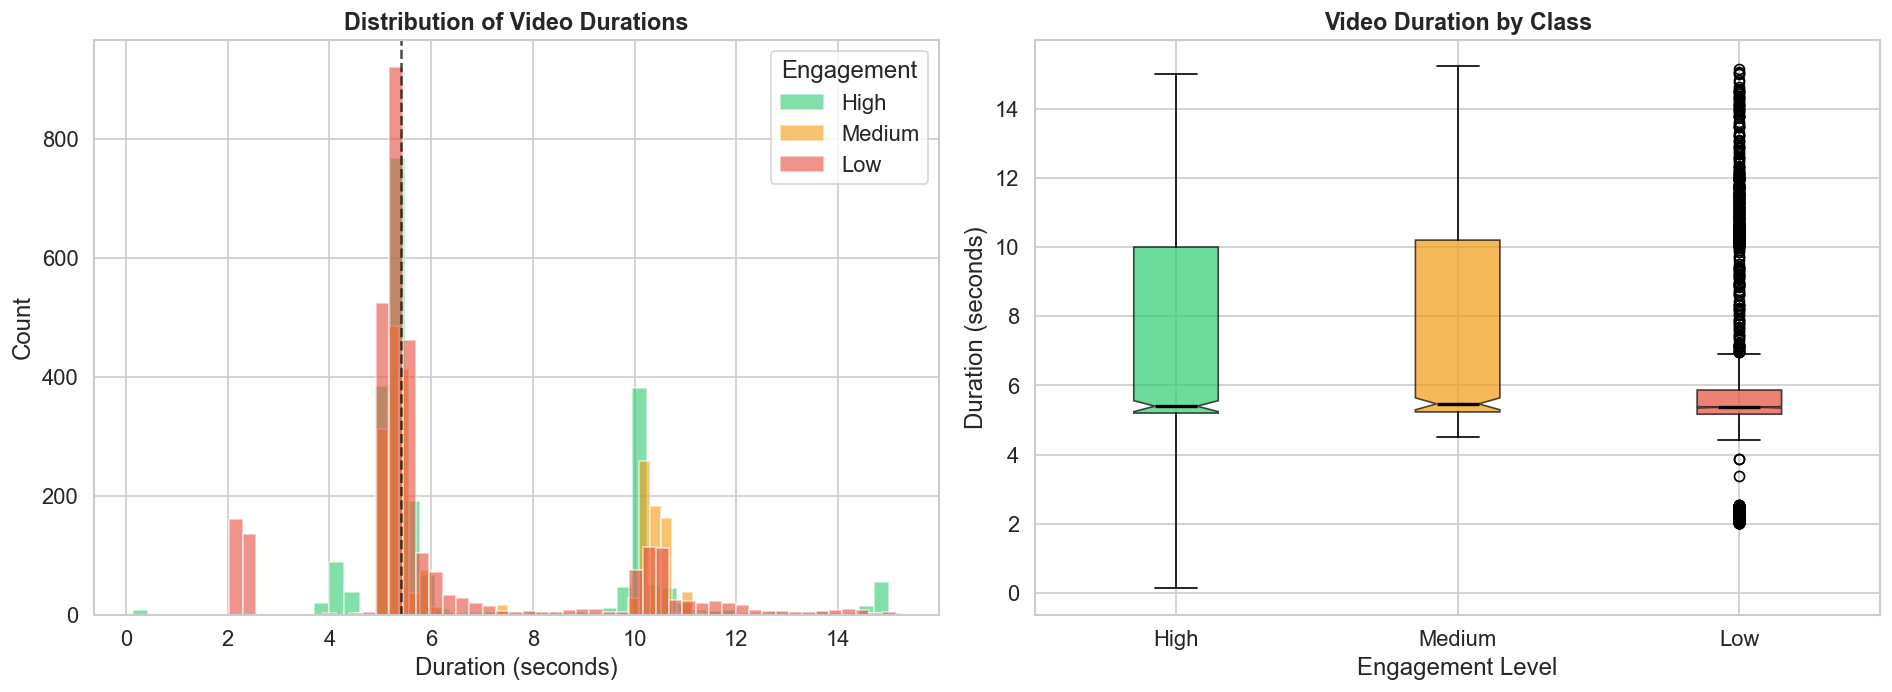

💾 Saved → E:\Video_Engagement\eda_results\duration_analysis.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Histogram of video durations ────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]['duration_sec']
    ax.hist(subset, bins=50, alpha=0.6, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Distribution of Video Durations', fontsize=14, fontweight='bold')
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Count')
ax.legend(title='Engagement')
ax.axvline(dur.median(), color='black', linestyle='--', alpha=0.7, label=f'Median={dur.median():.1f}s')

# ── Box plot per class ──────────────────────────────────────────────────────
ax = axes[1]
box_data = [df_valid[df_valid['class_label'] == cls]['duration_sec'].values for cls in CLASS_ORDER]
bp = ax.boxplot(box_data, labels=CLASS_ORDER, patch_artist=True, notch=True,
                medianprops={'color': 'black', 'linewidth': 2})
for patch, cls in zip(bp['boxes'], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.7)
ax.set_title('Video Duration by Class', fontsize=14, fontweight='bold')
ax.set_xlabel('Engagement Level')
ax.set_ylabel('Duration (seconds)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'duration_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "duration_analysis.png"}')

In [11]:
# ── Uniformity check ────────────────────────────────────────────────────────
cv_duration = dur.std() / dur.mean()  # Coefficient of Variation
print(f'\n📐 Duration Coefficient of Variation: {cv_duration:.4f}')
if cv_duration < 0.05:
    print('   ✅ Clips are approximately UNIFORM in length.')
    print('   → No temporal padding/truncation needed for batching.')
elif cv_duration < 0.3:
    print('   ⚠️  Clips have MODERATE duration variation.')
    print('   → Consider padding or adaptive pooling for batched training.')
else:
    print('   🚨 Clips have HIGH duration variation.')
    print('   → Must use padding, truncation, or sliding-window sampling.')


📐 Duration Coefficient of Variation: 0.3906
   🚨 Clips have HIGH duration variation.
   → Must use padding, truncation, or sliding-window sampling.


---
## 6. Frame Count Analysis

── Frame Count Statistics per Class ──


,min,max,mean,median,std
class_label,,,,,
High,4.0,450.0,205.88,162.0,81.06
Medium,108.0,457.0,210.70,163.0,72.70
Low,61.0,454.0,180.70,161.0,74.91


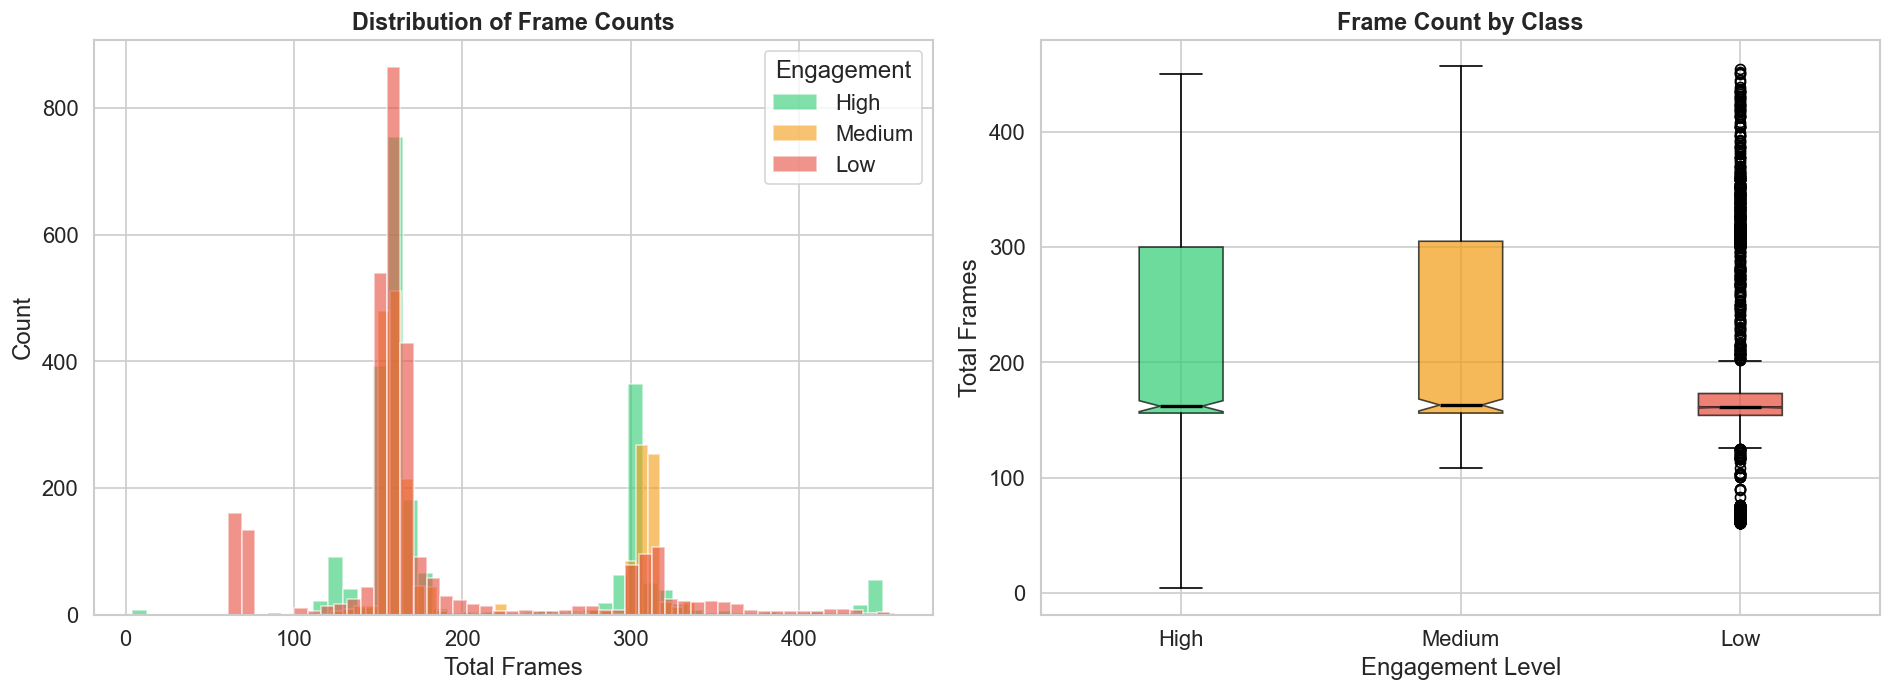

💾 Saved → E:\Video_Engagement\eda_results\frame_count_analysis.png


In [12]:
# ── Frame count statistics ──────────────────────────────────────────────────
frame_stats = (
    df_valid.groupby('class_label')['total_frames']
    .agg(['min', 'max', 'mean', 'median', 'std'])
    .reindex(CLASS_ORDER)
    .round(2)
)
print('── Frame Count Statistics per Class ──')
display(frame_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Histogram ───────────────────────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]['total_frames']
    ax.hist(subset, bins=50, alpha=0.6, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Distribution of Frame Counts', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Frames')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Box plot ────────────────────────────────────────────────────────────────
ax = axes[1]
box_data = [df_valid[df_valid['class_label'] == cls]['total_frames'].values for cls in CLASS_ORDER]
bp = ax.boxplot(box_data, labels=CLASS_ORDER, patch_artist=True, notch=True,
                medianprops={'color': 'black', 'linewidth': 2})
for patch, cls in zip(bp['boxes'], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.7)
ax.set_title('Frame Count by Class', fontsize=14, fontweight='bold')
ax.set_xlabel('Engagement Level')
ax.set_ylabel('Total Frames')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'frame_count_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "frame_count_analysis.png"}')

---
## 7. Resolution Analysis

In [13]:
# ── Resolution frequency table ──────────────────────────────────────────────
res_counts = df_valid['resolution'].value_counts()

print('── Resolution Frequency ──')
display(res_counts.to_frame('count').assign(
    percentage=lambda x: (x['count'] / x['count'].sum() * 100).round(2)
))

# ── Unique resolutions per class ────────────────────────────────────────────
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    unique_res = subset['resolution'].unique()
    print(f'  {cls}: {len(unique_res)} unique resolution(s) → {list(unique_res[:5])}')

── Resolution Frequency ──


,count,percentage
resolution,,
1920x1080,6537,88.77
1280x720,355,4.82
854x480,224,3.04
1064x598,180,2.44
1092x614,68,0.92


  High: 4 unique resolution(s) → ['1092x614', '1920x1080', '1280x720', '854x480']
  Medium: 1 unique resolution(s) → ['1920x1080']
  Low: 4 unique resolution(s) → ['1920x1080', '1280x720', '1064x598', '854x480']


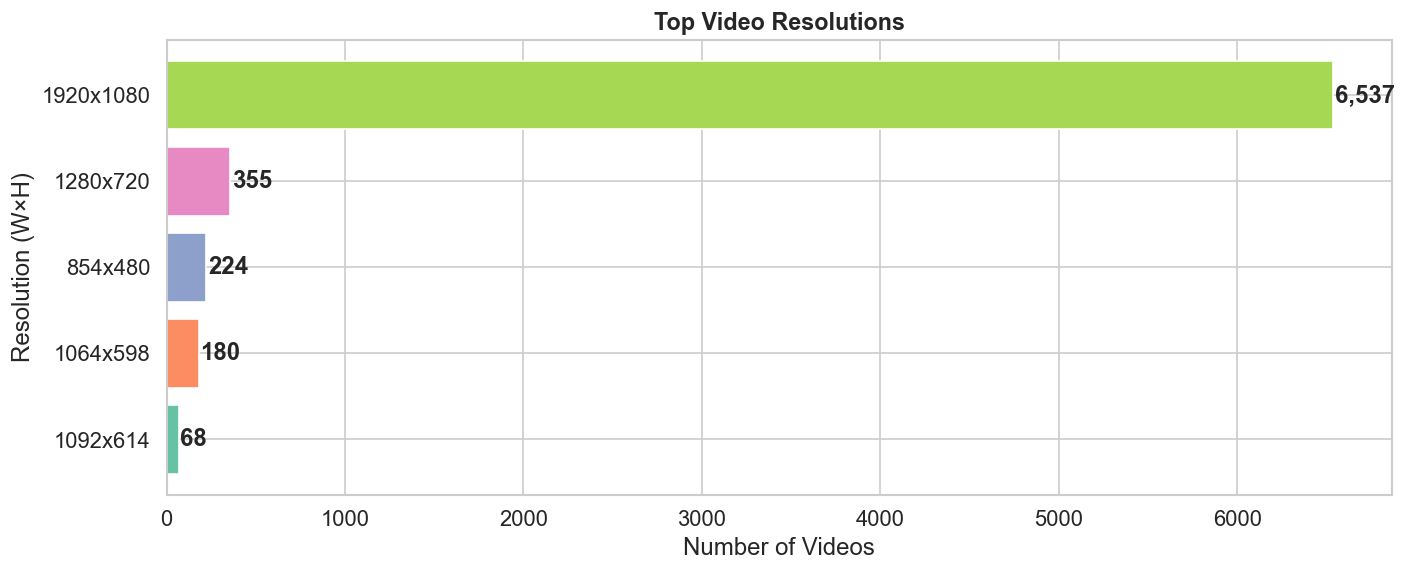

💾 Saved → E:\Video_Engagement\eda_results\resolution_analysis.png

⚠️  5 different resolutions detected.
   → Resizing to a common resolution is required for batched training.


In [14]:
# ── Resolution bar plot ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

res_top = res_counts.head(10)
bars = ax.barh(res_top.index[::-1], res_top.values[::-1],
               color=sns.color_palette('Set2', len(res_top)), edgecolor='white')
for bar, val in zip(bars, res_top.values[::-1]):
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontweight='bold')
ax.set_title('Top Video Resolutions', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Videos')
ax.set_ylabel('Resolution (W×H)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'resolution_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "resolution_analysis.png"}')

# ── Uniformity check ────────────────────────────────────────────────────────
n_unique = df_valid['resolution'].nunique()
if n_unique == 1:
    print(f'\n✅ All videos share the SAME resolution: {df_valid["resolution"].iloc[0]}')
    print('   → No resizing needed before model input.')
else:
    print(f'\n⚠️  {n_unique} different resolutions detected.')
    print('   → Resizing to a common resolution is required for batched training.')

---
## 8. FPS Analysis

In [15]:
# ── FPS statistics ──────────────────────────────────────────────────────────
fps_stats = (
    df_valid.groupby('class_label')['fps']
    .agg(['min', 'max', 'mean', 'median', 'std'])
    .reindex(CLASS_ORDER)
    .round(2)
)
print('── FPS Statistics per Class ──')
display(fps_stats)

# ── Overall FPS distribution ────────────────────────────────────────────────
fps_counts = df_valid['fps'].value_counts().sort_index()
print(f'\n── Unique FPS values: {df_valid["fps"].nunique()} ──')
print(fps_counts.to_string())

── FPS Statistics per Class ──


,min,max,mean,median,std
class_label,,,,,
High,13.26,30.0,29.91,30.0,0.60
Medium,20.18,30.0,29.84,30.0,0.82
Low,14.23,30.0,29.71,30.0,1.34



── Unique FPS values: 267 ──
fps
13.26       1
14.23       1
14.28       1
16.46       2
16.93       1
17.06       1
17.46       2
17.55       2
18.00       1
18.03       1
18.82       2
19.19       2
19.74       1
20.18       1
20.77       1
21.04       1
21.57       1
21.67       1
21.77       1
21.83       1
22.02       1
22.31       1
22.63       1
22.77       1
22.78       1
22.79       1
22.82       1
22.83       2
22.88       2
22.99       1
23.23       2
23.33       1
23.37       1
23.44       2
23.57       1
23.60       1
23.64       1
23.69       3
23.85       1
23.89       1
23.90       1
24.00       2
24.04       1
24.13       1
24.16       1
24.18       1
24.19       1
24.20       1
24.28       1
24.29       1
24.33       1
24.38       1
24.40       1
24.42       2
24.46       1
24.48       1
24.49       1
24.51       5
24.56       1
24.60       1
24.68       2
24.72       2
24.75       1
24.76       2
24.77       1
24.78       1
24.84       1
24.87       1
24.95       1


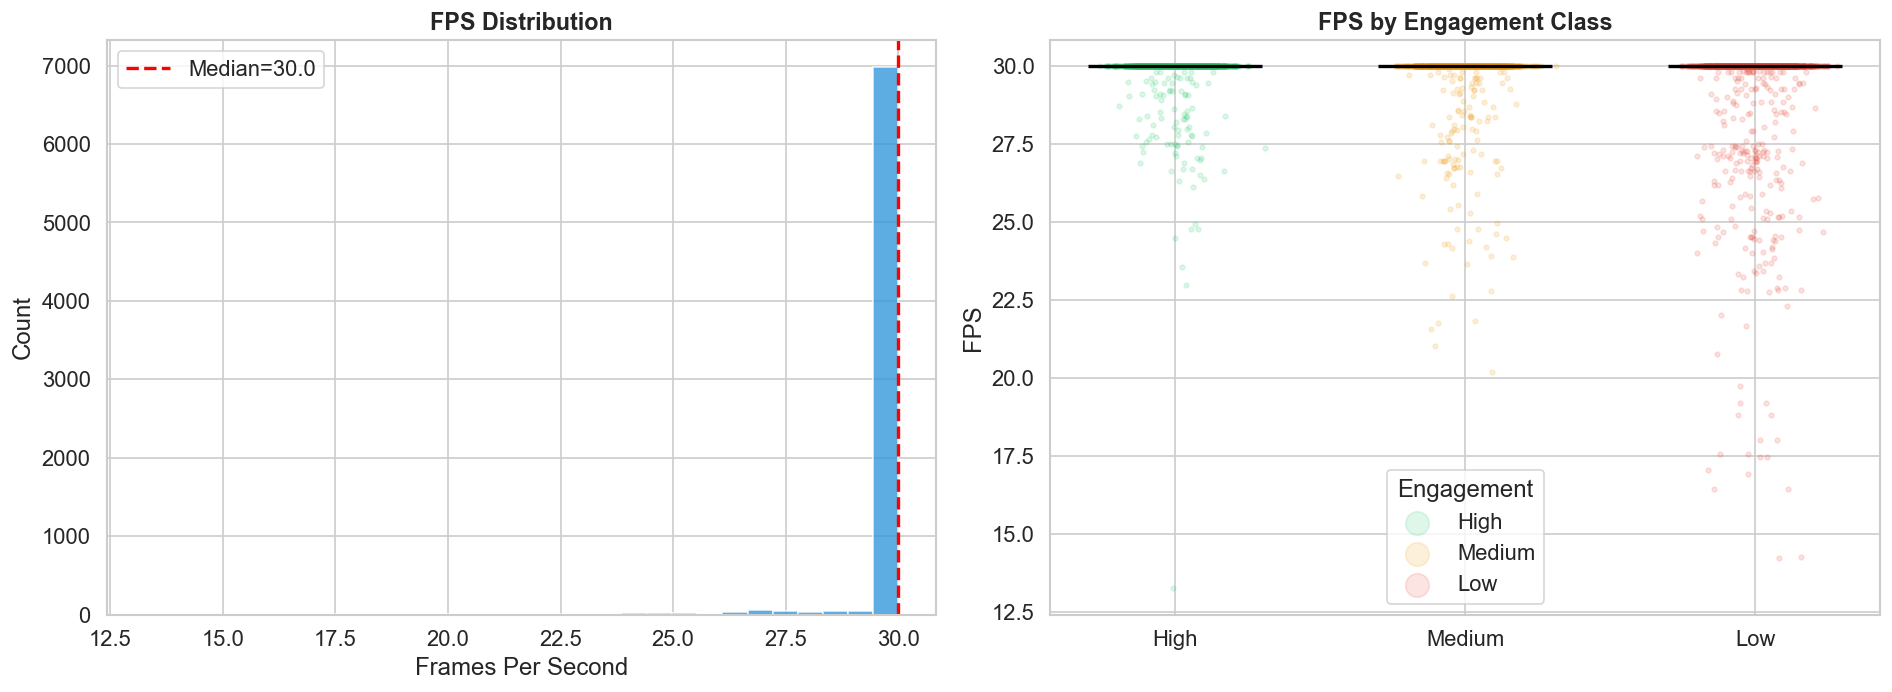

💾 Saved → E:\Video_Engagement\eda_results\fps_analysis.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── FPS histogram ───────────────────────────────────────────────────────────
ax = axes[0]
ax.hist(df_valid['fps'].dropna(), bins=30, color='#3498db', edgecolor='white', alpha=0.8)
ax.set_title('FPS Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Frames Per Second')
ax.set_ylabel('Count')
ax.axvline(df_valid['fps'].median(), color='red', linestyle='--', linewidth=2,
           label=f'Median={df_valid["fps"].median():.1f}')
ax.legend()

# ── FPS by class (strip plot) ───────────────────────────────────────────────
ax = axes[1]
for i, cls in enumerate(CLASS_ORDER):
    subset = df_valid[df_valid['class_label'] == cls]['fps']
    ax.scatter(np.random.normal(i, 0.08, size=len(subset)), subset,
               alpha=0.15, s=8, color=CLASS_COLORS[cls], label=cls)
    ax.hlines(subset.median(), i - 0.3, i + 0.3, colors='black', linewidth=2)
ax.set_xticks(range(len(CLASS_ORDER)))
ax.set_xticklabels(CLASS_ORDER)
ax.set_title('FPS by Engagement Class', fontsize=14, fontweight='bold')
ax.set_ylabel('FPS')
ax.legend(title='Engagement', markerscale=5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fps_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "fps_analysis.png"}')

In [17]:
# ── Impact on temporal models ───────────────────────────────────────────────
n_fps = df_valid['fps'].nunique()
print('\n═══════════════════════════════════════════════════════════')
print('  Impact on Temporal Models')
print('═══════════════════════════════════════════════════════════')
if n_fps == 1:
    print(f'  ✅ All videos have the SAME FPS ({df_valid["fps"].iloc[0]}).')
    print('     → Temporal sampling is straightforward.')
else:
    print(f'  ⚠️  {n_fps} different FPS values detected.')
    print('     → Temporal models (LSTMs, 3D-CNNs, TimeSformer) may need')
    print('       FPS normalisation to ensure consistent temporal stride.')
    print('     → Consider resampling all videos to a uniform FPS.')
print('═══════════════════════════════════════════════════════════')


═══════════════════════════════════════════════════════════
  Impact on Temporal Models
═══════════════════════════════════════════════════════════
  ⚠️  267 different FPS values detected.
     → Temporal models (LSTMs, 3D-CNNs, TimeSformer) may need
       FPS normalisation to ensure consistent temporal stride.
     → Consider resampling all videos to a uniform FPS.
═══════════════════════════════════════════════════════════


---
## 9. File Size Analysis

In [18]:
# ── File size statistics ────────────────────────────────────────────────────
size_stats = (
    df_valid.groupby('class_label')['file_size_mb']
    .agg(['min', 'max', 'mean', 'median', 'sum'])
    .reindex(CLASS_ORDER)
    .round(2)
)
size_stats.columns = ['Min (MB)', 'Max (MB)', 'Mean (MB)', 'Median (MB)', 'Total (MB)']
size_stats['Total (GB)'] = (size_stats['Total (MB)'] / 1024).round(2)

print('── File Size Statistics per Class ──')
display(size_stats)
print(f'\n📦 Total dataset size: {df_valid["file_size_mb"].sum() / 1024:.2f} GB')

── File Size Statistics per Class ──


,Min (MB),Max (MB),Mean (MB),Median (MB),Total (MB),Total (GB)
class_label,,,,,,
High,0.99,16.02,3.48,3.10,7924.85,7.74
Medium,1.86,14.10,4.22,3.45,8671.74,8.47
Low,0.49,10.79,3.23,2.82,9792.54,9.56



📦 Total dataset size: 25.77 GB


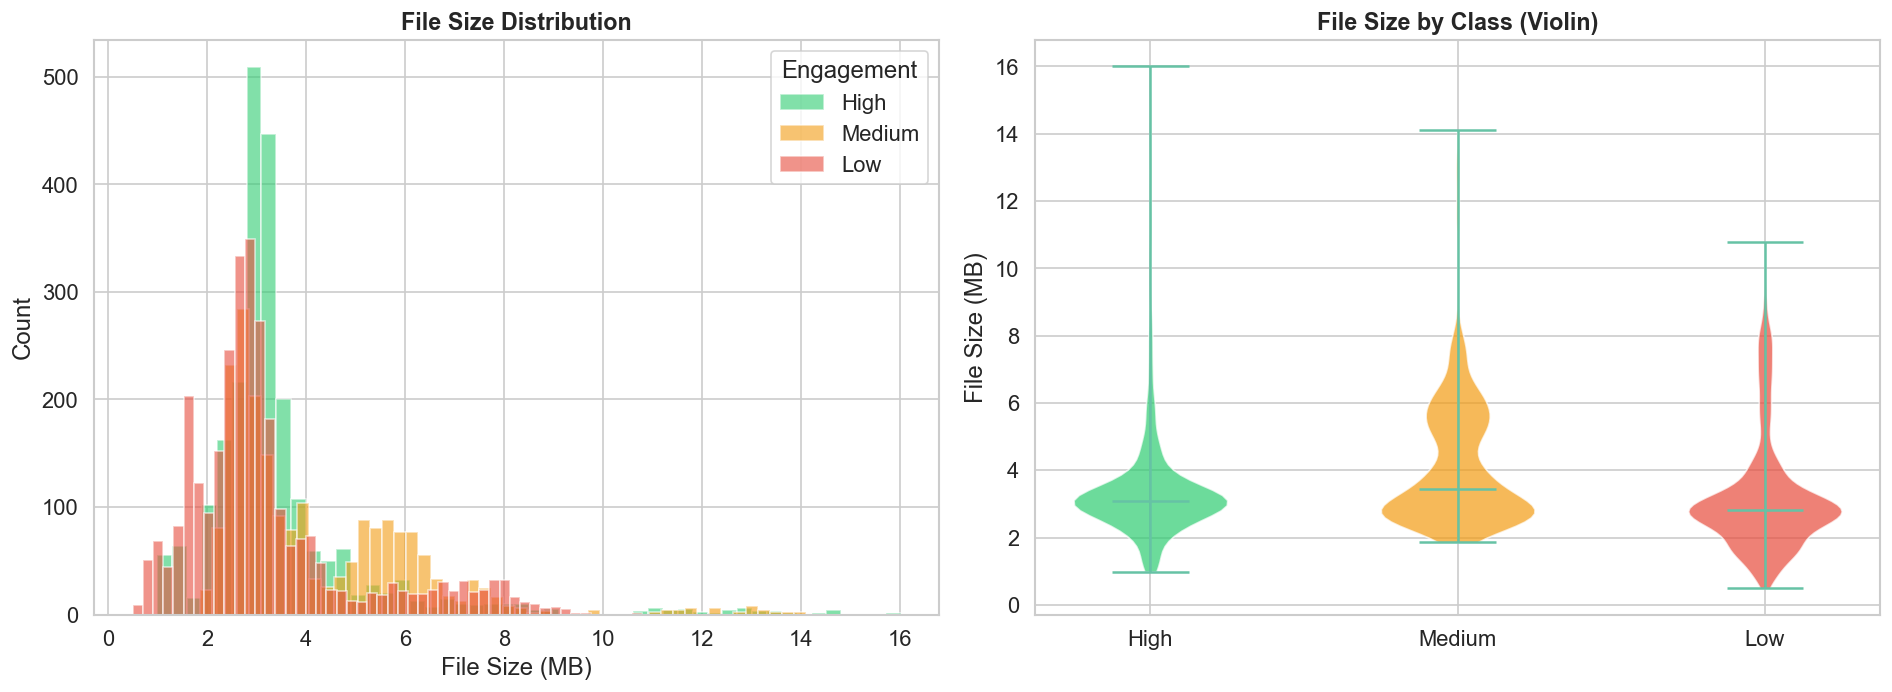

💾 Saved → E:\Video_Engagement\eda_results\file_size_analysis.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── File size histogram ─────────────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]['file_size_mb']
    ax.hist(subset, bins=50, alpha=0.6, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('File Size Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('File Size (MB)')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Class-wise comparison (violin) ──────────────────────────────────────────
ax = axes[1]
violin_data = [df_valid[df_valid['class_label'] == cls]['file_size_mb'].values for cls in CLASS_ORDER]
parts = ax.violinplot(violin_data, positions=range(len(CLASS_ORDER)), showmedians=True)
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(CLASS_COLORS[CLASS_ORDER[i]])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(CLASS_ORDER)))
ax.set_xticklabels(CLASS_ORDER)
ax.set_title('File Size by Class (Violin)', fontsize=14, fontweight='bold')
ax.set_ylabel('File Size (MB)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'file_size_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "file_size_analysis.png"}')

---
## 10. Visual Sample Inspection

For each engagement class, we randomly sample **N** videos and extract the **first**, **middle**, and **last** frames to visually inspect differences between engagement levels.

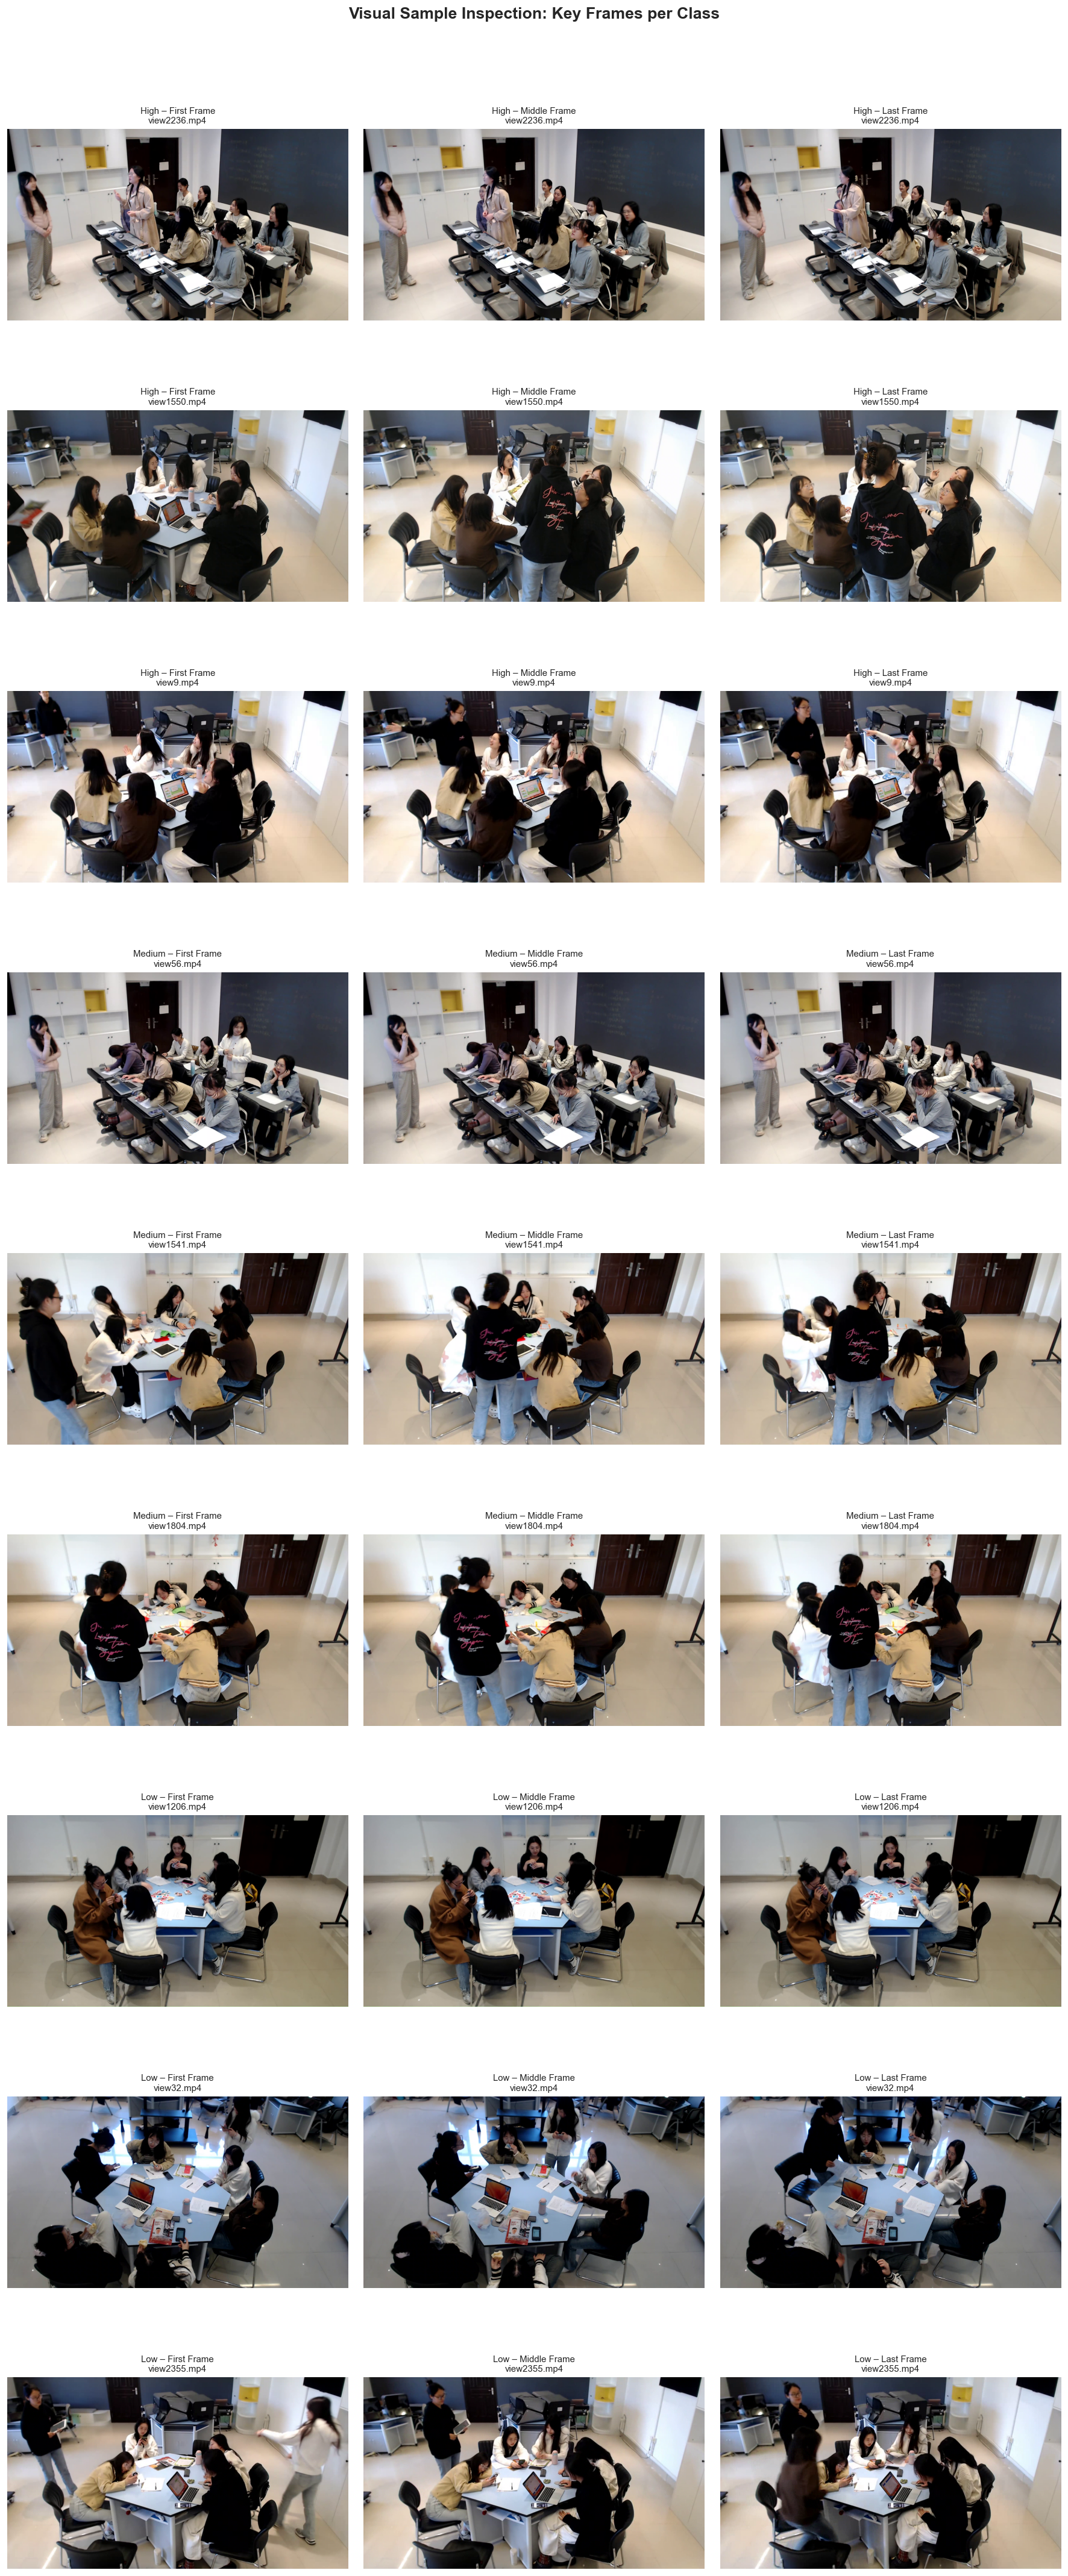

💾 Saved → E:\Video_Engagement\eda_results\visual_samples.png


In [20]:
N_SAMPLES = 3  # Number of videos to sample per class

def extract_key_frames(video_path: str):
    """Extract first, middle, and last frame from a video."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return None, None, None
    
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = {}
    
    for name, idx in [('first', 0), ('middle', total // 2), ('last', max(total - 2, 0))]:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret and frame is not None:
            frames[name] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        else:
            frames[name] = None
    
    cap.release()
    return frames.get('first'), frames.get('middle'), frames.get('last')


# ── Sample videos and extract frames ────────────────────────────────────────
fig, axes = plt.subplots(len(CLASS_ORDER) * N_SAMPLES, 3,
                          figsize=(15, 4 * len(CLASS_ORDER) * N_SAMPLES))

row_idx = 0
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    samples = subset.sample(n=min(N_SAMPLES, len(subset)), random_state=SEED)
    
    for _, sample_row in samples.iterrows():
        first, middle, last = extract_key_frames(sample_row['video_path'])
        
        for col_idx, (frame, title) in enumerate(
            [(first, 'First Frame'), (middle, 'Middle Frame'), (last, 'Last Frame')]
        ):
            ax = axes[row_idx, col_idx] if len(CLASS_ORDER) * N_SAMPLES > 1 else axes[col_idx]
            if frame is not None:
                ax.imshow(frame)
            else:
                ax.text(0.5, 0.5, 'N/A', ha='center', va='center', fontsize=14)
            ax.set_title(f'{cls} – {title}\n{sample_row["filename"]}', fontsize=9)
            ax.axis('off')
        
        row_idx += 1

plt.suptitle('Visual Sample Inspection: Key Frames per Class',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'visual_samples.png', bbox_inches='tight')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "visual_samples.png"}')

---
## 11. Frame-Level Analysis

For a sample of videos per class, we extract uniformly-spaced frames and compute:
- **Average pixel intensity** (brightness proxy)
- **Contrast** (standard deviation of pixel values)
- **Per-channel (B, G, R) mean** for colour distribution analysis

In [21]:
N_SAMPLE_VIDEOS = 30   # Videos to sample per class
N_FRAMES_PER_VIDEO = 5 # Frames to sample per video

def analyse_video_frames(video_path: str, n_frames: int = 5) -> list:
    """Sample n_frames uniformly from a video and compute intensity stats."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return []
    
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return []
    
    indices = np.linspace(0, total - 1, n_frames, dtype=int)
    results = []
    
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret or frame is None:
            continue
        
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        results.append({
            'brightness': float(gray.mean()),
            'contrast':   float(gray.std()),
            'mean_b':     float(frame[:, :, 0].mean()),
            'mean_g':     float(frame[:, :, 1].mean()),
            'mean_r':     float(frame[:, :, 2].mean()),
        })
    
    cap.release()
    return results


print(f'🔄 Sampling {N_SAMPLE_VIDEOS} videos/class × {N_FRAMES_PER_VIDEO} frames/video...')

frame_analysis_records = []
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    samples = subset.sample(n=min(N_SAMPLE_VIDEOS, len(subset)), random_state=SEED)
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc=f'{cls}'):
        frame_stats_list = analyse_video_frames(row['video_path'], N_FRAMES_PER_VIDEO)
        for fs in frame_stats_list:
            fs['class_label'] = cls
            fs['filename'] = row['filename']
            frame_analysis_records.append(fs)

df_frames = pd.DataFrame(frame_analysis_records)
print(f'\n✅ Analysed {len(df_frames)} frames total.')
display(df_frames.groupby('class_label')[['brightness', 'contrast']].describe().round(2))

🔄 Sampling 30 videos/class × 5 frames/video...


High:   0%|          | 0/30 [00:00<?, ?it/s]

Medium:   0%|          | 0/30 [00:00<?, ?it/s]

Low:   0%|          | 0/30 [00:00<?, ?it/s]


✅ Analysed 448 frames total.


brightness                                                         \
                 count    mean    std     min     25%     50%     75%     max   
class_label                                                                     
High             149.0  125.84  11.38  106.54  117.36  124.67  135.14  145.83   
Low              149.0  113.78  11.31   92.65  106.68  110.42  117.20  145.28   
Medium           150.0  124.76  12.14  100.60  113.82  129.52  135.49  143.81   

            contrast                                                  
               count   mean   std    min    25%    50%    75%    max  
class_label                                                           
High           149.0  77.12  7.29  64.30  73.13  75.62  82.78  92.47  
Low            149.0  72.03  6.13  62.44  65.38  73.53  75.67  84.47  
Medium         150.0  76.41  5.22  66.04  72.98  76.62  80.03  86.91

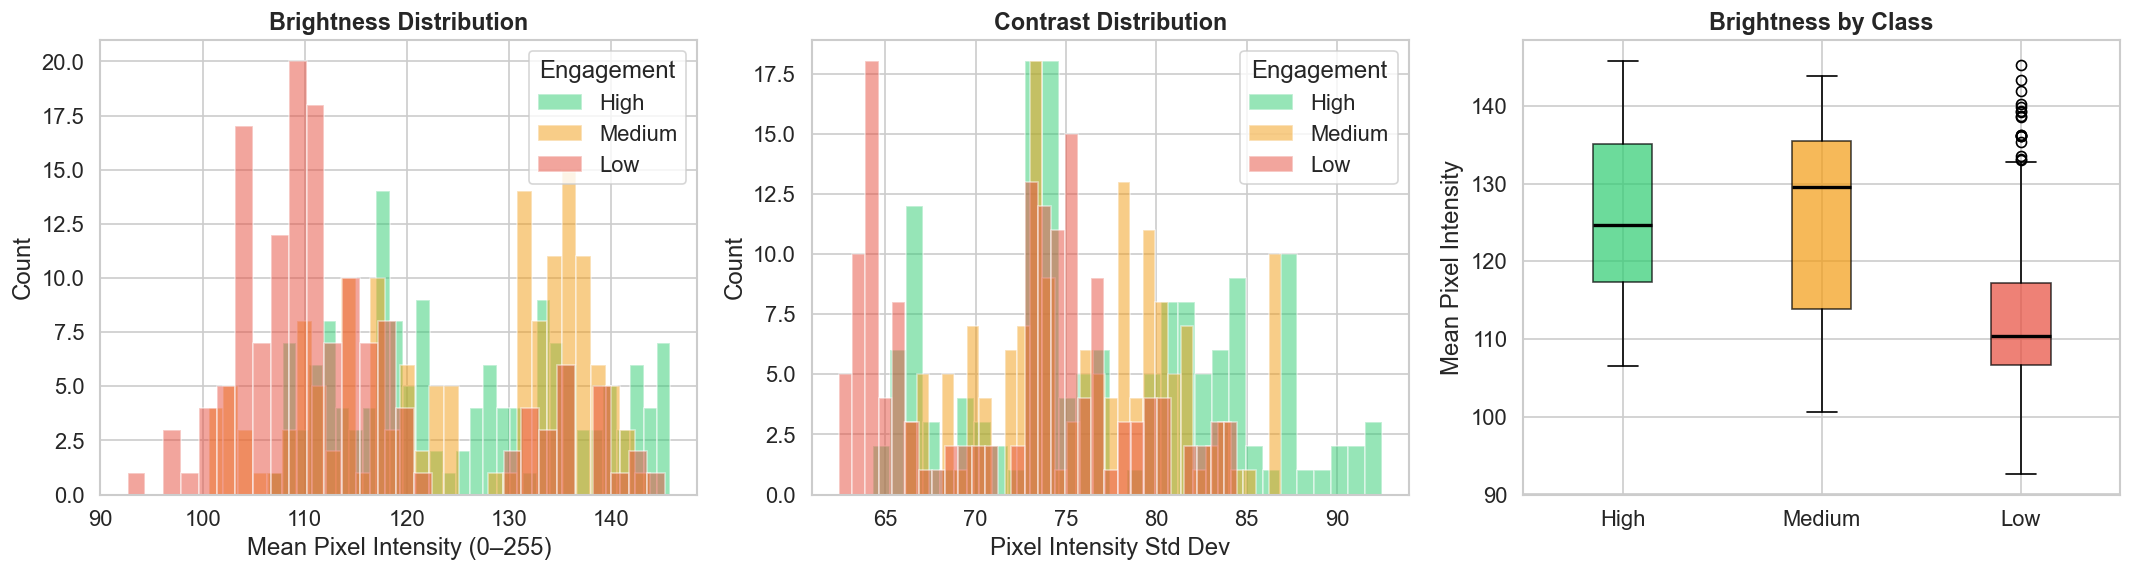

💾 Saved → E:\Video_Engagement\eda_results\frame_level_analysis.png


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Brightness comparison ───────────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_frames[df_frames['class_label'] == cls]['brightness']
    ax.hist(subset, bins=30, alpha=0.5, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Brightness Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Pixel Intensity (0–255)')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Contrast comparison ─────────────────────────────────────────────────────
ax = axes[1]
for cls in CLASS_ORDER:
    subset = df_frames[df_frames['class_label'] == cls]['contrast']
    ax.hist(subset, bins=30, alpha=0.5, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Contrast Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Pixel Intensity Std Dev')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Box plot: brightness by class ───────────────────────────────────────────
ax = axes[2]
box_data = [df_frames[df_frames['class_label'] == cls]['brightness'].values for cls in CLASS_ORDER]
bp = ax.boxplot(box_data, labels=CLASS_ORDER, patch_artist=True,
                medianprops={'color': 'black', 'linewidth': 2})
for patch, cls in zip(bp['boxes'], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.7)
ax.set_title('Brightness by Class', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean Pixel Intensity')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'frame_level_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "frame_level_analysis.png"}')

---
## 12. Motion Analysis

We compute a simple proxy for motion by measuring the **average absolute frame difference** between consecutive sampled frames. Higher values indicate more movement in the scene.

In [23]:
N_MOTION_SAMPLES = 30  # Videos per class

def compute_motion_score(video_path: str, sample_pairs: int = 10) -> float:
    """
    Estimate average motion by computing mean absolute frame difference
    over `sample_pairs` uniformly-spaced consecutive frame pairs.
    
    Returns the mean motion intensity (0–255 scale).
    """
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return np.nan
    
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 2:
        cap.release()
        return np.nan
    
    # Sample frame indices (consecutive pairs)
    indices = np.linspace(0, total - 2, min(sample_pairs, total - 1), dtype=int)
    diffs = []
    
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret1, frame1 = cap.read()
        ret2, frame2 = cap.read()
        
        if ret1 and ret2 and frame1 is not None and frame2 is not None:
            gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
            gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)
            diff = cv2.absdiff(gray1, gray2)
            diffs.append(diff.mean())
    
    cap.release()
    return float(np.mean(diffs)) if diffs else np.nan


print(f'🔄 Computing motion scores ({N_MOTION_SAMPLES} videos/class)...')

motion_records = []
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    samples = subset.sample(n=min(N_MOTION_SAMPLES, len(subset)), random_state=SEED)
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc=f'{cls}'):
        score = compute_motion_score(row['video_path'])
        motion_records.append({
            'filename': row['filename'],
            'class_label': cls,
            'motion_score': score,
        })

df_motion = pd.DataFrame(motion_records)
df_motion_clean = df_motion.dropna(subset=['motion_score'])

print(f'\n✅ Motion scores computed for {len(df_motion_clean)} videos.')

# ── Per-class summary ───────────────────────────────────────────────────────
motion_summary = (
    df_motion_clean.groupby('class_label')['motion_score']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .reindex(CLASS_ORDER)
    .round(3)
)
print('\n── Motion Statistics per Class ──')
display(motion_summary)

🔄 Computing motion scores (30 videos/class)...


High:   0%|          | 0/30 [00:00<?, ?it/s]

Medium:   0%|          | 0/30 [00:00<?, ?it/s]

Low:   0%|          | 0/30 [00:00<?, ?it/s]


✅ Motion scores computed for 90 videos.

── Motion Statistics per Class ──


,mean,median,std,min,max
class_label,,,,,
High,1.298,1.196,0.461,0.782,3.047
Medium,1.109,1.006,0.552,0.347,2.831
Low,1.163,1.062,0.579,0.270,2.455


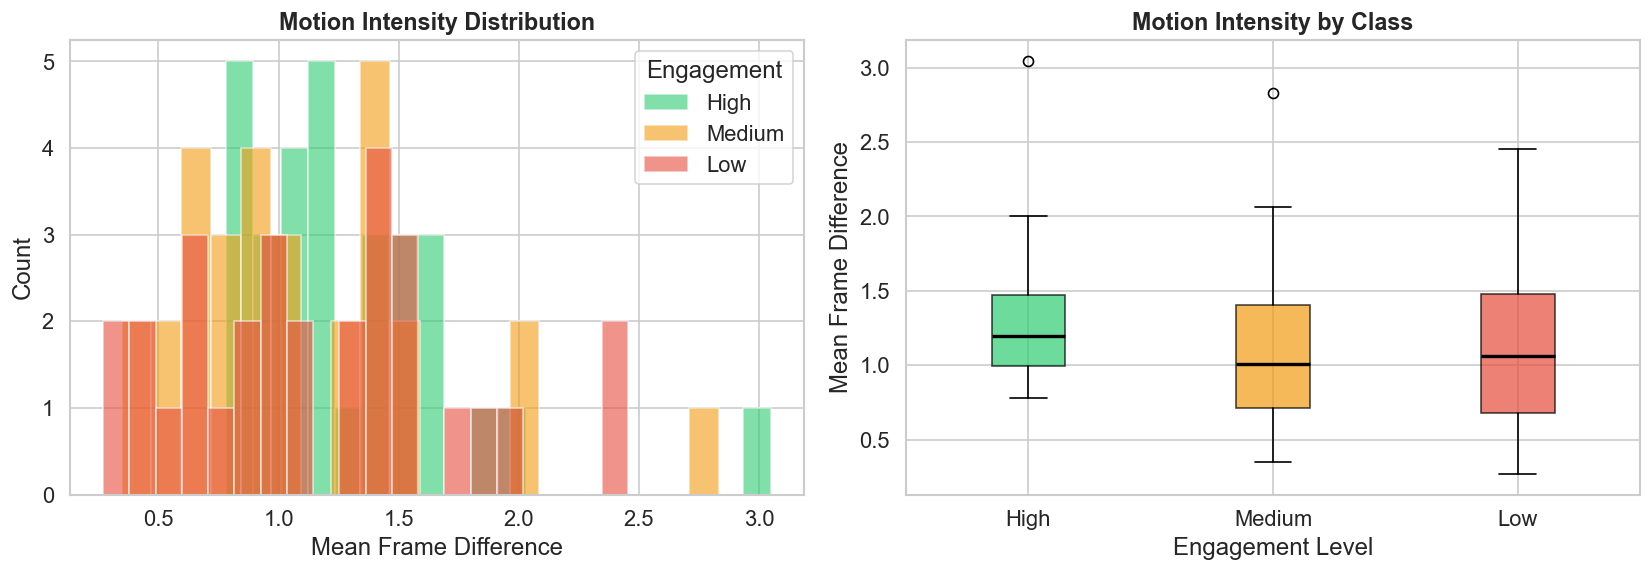

💾 Saved → E:\Video_Engagement\eda_results\motion_analysis.png

── Motion–Engagement Correlation Interpretation ──
  📈 Higher engagement → MORE motion (students moving/interacting).
     This suggests motion features could be discriminative for engagement.


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Motion histogram ────────────────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_motion_clean[df_motion_clean['class_label'] == cls]['motion_score']
    ax.hist(subset, bins=20, alpha=0.6, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Motion Intensity Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Frame Difference')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Motion box plot ─────────────────────────────────────────────────────────
ax = axes[1]
box_data = [df_motion_clean[df_motion_clean['class_label'] == cls]['motion_score'].values
            for cls in CLASS_ORDER]
bp = ax.boxplot(box_data, labels=CLASS_ORDER, patch_artist=True,
                medianprops={'color': 'black', 'linewidth': 2})
for patch, cls in zip(bp['boxes'], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.7)
ax.set_title('Motion Intensity by Class', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean Frame Difference')
ax.set_xlabel('Engagement Level')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'motion_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "motion_analysis.png"}')

# ── Interpretation ──────────────────────────────────────────────────────────
means = motion_summary['mean']
print('\n── Motion–Engagement Correlation Interpretation ──')
if means.get('High', 0) > means.get('Low', 0):
    print('  📈 Higher engagement → MORE motion (students moving/interacting).')
    print('     This suggests motion features could be discriminative for engagement.')
elif means.get('Low', 0) > means.get('High', 0):
    print('  📉 Lower engagement → MORE motion (possible restlessness/distraction).')
    print('     Motion patterns may reflect disengagement behaviour.')
else:
    print('  ≈ No clear directional trend between motion and engagement.')
    print('     Engagement differences may be driven by other visual cues.')

---
## 13. Advanced CV Analysis — Face Detection

Using OpenCV's Haar Cascade classifier, we detect faces in sampled frames to estimate the **number of visible people** and how face-count distributions differ across engagement levels.

> ⚠️ Haar cascades are lightweight but less accurate than deep-learning detectors. Results are approximate.

In [25]:
N_FACE_SAMPLES = 20      # Videos per class
N_FACE_FRAMES  = 3       # Frames per video

# ── Load Haar cascade ───────────────────────────────────────────────────────
cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)
assert not face_cascade.empty(), 'Failed to load Haar cascade.'
print(f'✅ Haar cascade loaded from: {cascade_path}')


def count_faces_in_video(video_path: str, n_frames: int = 3) -> list:
    """Detect faces in n_frames uniformly sampled from the video."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return []
    
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return []
    
    indices = np.linspace(0, total - 1, n_frames, dtype=int)
    face_counts = []
    
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret or frame is None:
            continue
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1,
                                              minNeighbors=5, minSize=(30, 30))
        face_counts.append(len(faces))
    
    cap.release()
    return face_counts


print(f'🔄 Running face detection ({N_FACE_SAMPLES} videos/class × {N_FACE_FRAMES} frames)...')

face_records = []
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    samples = subset.sample(n=min(N_FACE_SAMPLES, len(subset)), random_state=SEED)
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc=f'{cls}'):
        counts = count_faces_in_video(row['video_path'], N_FACE_FRAMES)
        for c in counts:
            face_records.append({
                'filename': row['filename'],
                'class_label': cls,
                'face_count': c,
            })

df_faces = pd.DataFrame(face_records)
print(f'\n✅ Face detection complete: {len(df_faces)} frame samples.')

face_summary = (
    df_faces.groupby('class_label')['face_count']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .reindex(CLASS_ORDER)
    .round(2)
)
print('\n── Face Detection Statistics per Class ──')
display(face_summary)

✅ Haar cascade loaded from: c:\Users\koppe\anaconda3\Lib\site-packages\cv2\data\haarcascade_frontalface_default.xml
🔄 Running face detection (20 videos/class × 3 frames)...


High:   0%|          | 0/20 [00:00<?, ?it/s]

Medium:   0%|          | 0/20 [00:00<?, ?it/s]

Low:   0%|          | 0/20 [00:00<?, ?it/s]


✅ Face detection complete: 179 frame samples.

── Face Detection Statistics per Class ──


,mean,median,std,min,max
class_label,,,,,
High,2.05,2.0,1.21,0,5
Medium,1.47,1.0,1.07,0,5
Low,1.63,2.0,1.19,0,5


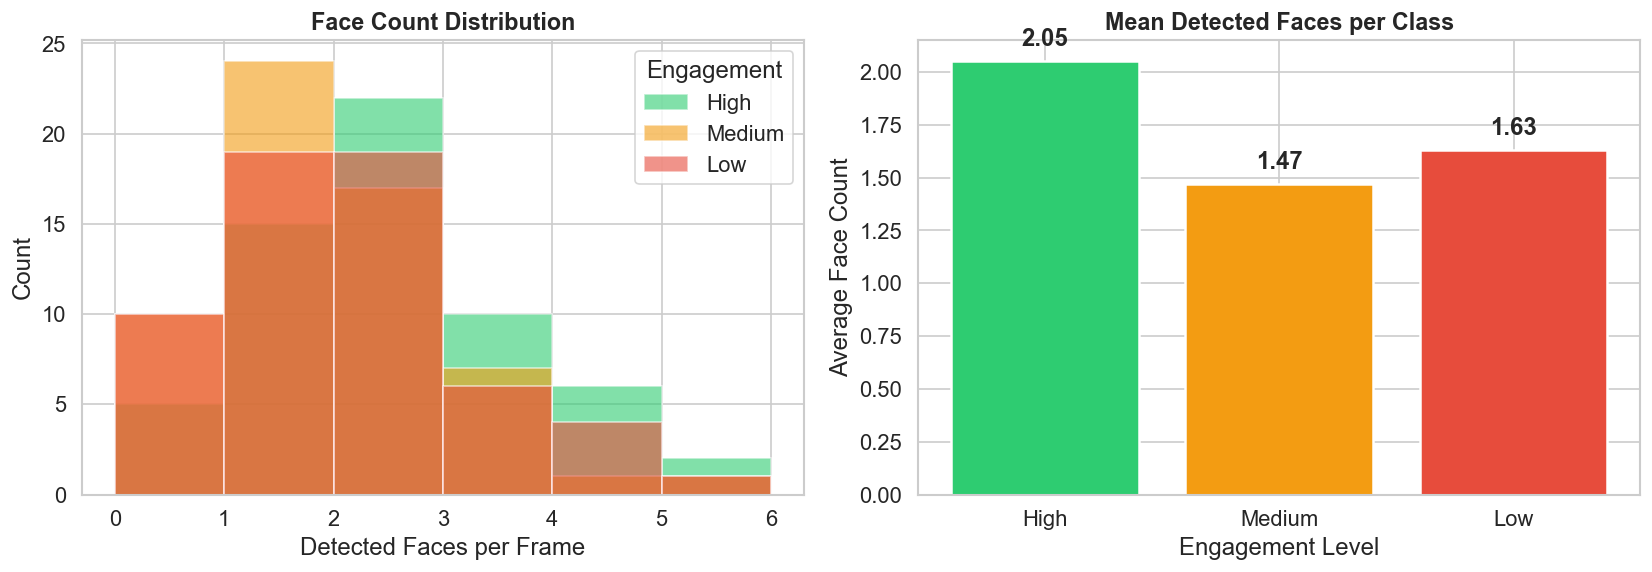

💾 Saved → E:\Video_Engagement\eda_results\face_detection_analysis.png


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Face count distribution ─────────────────────────────────────────────────
ax = axes[0]
for cls in CLASS_ORDER:
    subset = df_faces[df_faces['class_label'] == cls]['face_count']
    ax.hist(subset, bins=range(0, int(df_faces['face_count'].max()) + 2),
            alpha=0.6, label=cls, color=CLASS_COLORS[cls], edgecolor='white')
ax.set_title('Face Count Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Detected Faces per Frame')
ax.set_ylabel('Count')
ax.legend(title='Engagement')

# ── Mean face count by class ────────────────────────────────────────────────
ax = axes[1]
means = face_summary['mean']
bars = ax.bar(means.index, means.values,
              color=[CLASS_COLORS[c] for c in means.index],
              edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, means.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{val:.2f}', ha='center', va='bottom', fontweight='bold')
ax.set_title('Mean Detected Faces per Class', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Face Count')
ax.set_xlabel('Engagement Level')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'face_detection_analysis.png')
plt.show()
print(f'💾 Saved → {OUTPUT_DIR / "face_detection_analysis.png"}')

---
## 14. Dataset Quality Checks

We identify and report:
- **Corrupted videos** (unreadable by OpenCV)
- **Missing metadata** (zero-dimension, zero-FPS, or zero-frame videos)
- **Duplicate filenames** across or within classes

In [27]:
# ── Corrupted videos ────────────────────────────────────────────────────────
corrupted = df_meta[df_meta['is_corrupted']]
print('════════════════════════════════════════════════════════════')
print('  Dataset Quality Report')
print('════════════════════════════════════════════════════════════')
print(f'  Total videos            : {len(df_meta):>6,}')
print(f'  ✅ Valid (readable)      : {len(df_valid):>6,}')
print(f'  ❌ Corrupted/unreadable  : {len(corrupted):>6,}')

if len(corrupted) > 0:
    print('\n  ── Corrupted files ──')
    for _, row in corrupted.iterrows():
        print(f'    {row["class_label"]:8s} │ {row["filename"]}')
    print(f'\n  ⚠️  Remove or re-download these {len(corrupted)} files before training.')
else:
    print('  ✅ No corrupted files detected.')

════════════════════════════════════════════════════════════
  Dataset Quality Report
════════════════════════════════════════════════════════════
  Total videos            :  7,439
  ✅ Valid (readable)      :  7,364
  ❌ Corrupted/unreadable  :     75

  ── Corrupted files ──
    High     │ view2521.mp4
    High     │ view2630.mp4
    High     │ view2631.mp4
    High     │ view2632.mp4
    High     │ view1316.mp4
    High     │ view1319.mp4
    High     │ view1322.mp4
    High     │ view1325.mp4
    High     │ view1328.mp4
    High     │ view1331.mp4
    High     │ view1334.mp4
    High     │ view1337.mp4
    High     │ view1340.mp4
    High     │ view1343.mp4
    High     │ view1346.mp4
    High     │ view1349.mp4
    High     │ view1352.mp4
    High     │ view1355.mp4
    High     │ view1358.mp4
    High     │ view1361.mp4
    High     │ view1364.mp4
    High     │ view1367.mp4
    High     │ view1370.mp4
    High     │ view1373.mp4
    High     │ view1376.mp4
    High     │ view1379

In [28]:
# ── Missing metadata ────────────────────────────────────────────────────────
zero_dims   = df_valid[(df_valid['width'] == 0) | (df_valid['height'] == 0)]
zero_fps    = df_valid[df_valid['fps'] == 0]
zero_frames = df_valid[df_valid['total_frames'] == 0]

print(f'\n  Videos with zero dimensions : {len(zero_dims)}')
print(f'  Videos with zero FPS        : {len(zero_fps)}')
print(f'  Videos with zero frames     : {len(zero_frames)}')

# ── Duplicate filenames ─────────────────────────────────────────────────────
dup_names = df_meta[df_meta.duplicated(subset='filename', keep=False)]
n_dup_unique = dup_names['filename'].nunique()

print(f'\n  Duplicate filenames         : {n_dup_unique} unique names ({len(dup_names)} total occurrences)')
if n_dup_unique > 0 and n_dup_unique <= 20:
    print('  ── Sample duplicates ──')
    for name in dup_names['filename'].unique()[:10]:
        classes = dup_names[dup_names['filename'] == name]['class_label'].tolist()
        print(f'    {name}: appears in {classes}')

print('\n════════════════════════════════════════════════════════════')
print('  Quality Assessment: ', end='')
issues = len(corrupted) + len(zero_dims) + len(zero_fps) + len(zero_frames)
if issues == 0:
    print('EXCELLENT ✅')
    print('  No quality issues detected. Dataset is ready for training.')
elif issues < 10:
    print('GOOD ⚠️')
    print(f'  {issues} minor issue(s). Consider cleaning before training.')
else:
    print('NEEDS ATTENTION 🚨')
    print(f'  {issues} issue(s) found. Data cleaning recommended.')
print('════════════════════════════════════════════════════════════')


  Videos with zero dimensions : 0
  Videos with zero FPS        : 0
  Videos with zero frames     : 0

  Duplicate filenames         : 2636 unique names (7046 total occurrences)

════════════════════════════════════════════════════════════
  Quality Assessment: NEEDS ATTENTION 🚨
  75 issue(s) found. Data cleaning recommended.
════════════════════════════════════════════════════════════


---
## 15. Research-Oriented Summary — EDA Findings

In [29]:
# ── Auto-generated EDA findings ─────────────────────────────────────────────
from IPython.display import Markdown, display as ipy_display

# Gather statistics
total_videos  = len(df_meta)
valid_videos  = len(df_valid)
n_corrupted   = len(corrupted)
total_hours   = df_valid['duration_sec'].sum() / 3600
total_size_gb = df_valid['file_size_mb'].sum() / 1024

class_str = '\n'.join([
    f'  - **{cls}**: {class_counts[cls]:,} videos ({class_counts[cls]/total_videos*100:.1f}%)'
    for cls in CLASS_ORDER
])

res_str = ', '.join(res_counts.head(3).index)
n_res = df_valid['resolution'].nunique()

fps_vals = df_valid['fps'].unique()
fps_str  = ', '.join([f'{f:.1f}' for f in sorted(fps_vals)[:5]])

summary_md = f"""
# 📋 EDA Findings — OUC-CGE Video Engagement Dataset

## 1. Dataset Size
- **Total videos**: {total_videos:,}
- **Valid (readable) videos**: {valid_videos:,}
- **Corrupted videos**: {n_corrupted}
- **Total duration**: {total_hours:.1f} hours
- **Total storage**: {total_size_gb:.2f} GB

## 2. Class Distribution
{class_str}
- **Imbalance ratio** (max/min): **{imbalance_ratio:.2f}**
- Assessment: {'Balanced ✅' if imbalance_ratio < 1.5 else 'Moderately imbalanced ⚠️' if imbalance_ratio < 3 else 'Highly imbalanced 🚨'}

## 3. Temporal Properties
- **Duration range**: {dur.min():.2f}s – {dur.max():.2f}s
- **Mean duration**: {dur.mean():.2f}s (median: {dur.median():.2f}s)
- **Duration CV**: {cv_duration:.4f} ({'uniform' if cv_duration < 0.05 else 'moderate variation' if cv_duration < 0.3 else 'high variation'})
- **FPS values**: {fps_str}{'...' if len(fps_vals) > 5 else ''} ({len(fps_vals)} unique)

## 4. Spatial Properties
- **Resolutions**: {n_res} unique ({res_str})
- {'All videos share the same resolution.' if n_res == 1 else 'Multiple resolutions detected — resizing required.'}

## 5. Visual Properties
- Brightness and contrast vary across classes (see frame-level analysis)
- Motion intensity analysed via frame differencing
- Face detection provides approximate people counts

## 6. Challenges
- {'Class imbalance requires mitigation (weighted loss, oversampling)' if imbalance_ratio >= 1.5 else 'Class distribution is balanced'}
- {'Variable video durations require padding or truncation' if cv_duration >= 0.05 else 'Uniform clip lengths simplify batching'}
- {'Multiple resolutions require standardisation' if n_res > 1 else 'Uniform resolution simplifies preprocessing'}
- {'Multiple FPS values need temporal resampling' if len(fps_vals) > 1 else 'Consistent FPS simplifies temporal modelling'}
- Classroom videos may have occlusions, varied lighting, and camera angles

## 7. Implications for Model Design
- **Input pipeline**: Resize to common resolution, normalise FPS, apply temporal sampling
- **Architecture**: Consider 3D-CNNs (C3D, I3D), Video Transformers (TimeSformer, ViViT), or 2D-CNN + LSTM
- **Training strategy**: {'Use class-weighted loss or oversampling' if imbalance_ratio >= 1.5 else 'Standard training'}, stratified splits
- **Augmentation**: Random crops, horizontal flips, temporal jittering, colour augmentation
- **Evaluation**: Report per-class metrics (precision, recall, F1) alongside overall accuracy
"""

ipy_display(Markdown(summary_md))


# 📋 EDA Findings — OUC-CGE Video Engagement Dataset

## 1. Dataset Size
- **Total videos**: 7,439
- **Valid (readable) videos**: 7,364
- **Corrupted videos**: 75
- **Total duration**: 13.5 hours
- **Total storage**: 25.77 GB

## 2. Class Distribution
  - **High**: 2,345 videos (31.5%)
  - **Medium**: 2,053 videos (27.6%)
  - **Low**: 3,041 videos (40.9%)
- **Imbalance ratio** (max/min): **1.48**
- Assessment: Balanced ✅

## 3. Temporal Properties
- **Duration range**: 0.13s – 15.23s
- **Mean duration**: 6.60s (median: 5.40s)
- **Duration CV**: 0.3906 (high variation)
- **FPS values**: 13.3, 14.2, 14.3, 16.5, 16.9... (267 unique)

## 4. Spatial Properties
- **Resolutions**: 5 unique (1920x1080, 1280x720, 854x480)
- Multiple resolutions detected — resizing required.

## 5. Visual Properties
- Brightness and contrast vary across classes (see frame-level analysis)
- Motion intensity analysed via frame differencing
- Face detection provides approximate people counts

## 6. Challenges
- Class distribution is balanced
- Variable video durations require padding or truncation
- Multiple resolutions require standardisation
- Multiple FPS values need temporal resampling
- Classroom videos may have occlusions, varied lighting, and camera angles

## 7. Implications for Model Design
- **Input pipeline**: Resize to common resolution, normalise FPS, apply temporal sampling
- **Architecture**: Consider 3D-CNNs (C3D, I3D), Video Transformers (TimeSformer, ViViT), or 2D-CNN + LSTM
- **Training strategy**: Standard training, stratified splits
- **Augmentation**: Random crops, horizontal flips, temporal jittering, colour augmentation
- **Evaluation**: Report per-class metrics (precision, recall, F1) alongside overall accuracy


---
## 16. Export Results

All saved outputs:

In [30]:
# ── List all exported files ─────────────────────────────────────────────────
print('═══════════════════════════════════════════════════════════')
print('  Exported Files')
print('═══════════════════════════════════════════════════════════')

exported_files = [
    ('metadata.csv',              'Complete video metadata for all videos'),
    ('class_distribution.png',    'Bar + pie chart of class distribution'),
    ('duration_analysis.png',     'Duration histogram + box plot'),
    ('frame_count_analysis.png',  'Frame count histogram + box plot'),
    ('resolution_analysis.png',   'Resolution frequency bar chart'),
    ('fps_analysis.png',          'FPS distribution + per-class strip plot'),
    ('file_size_analysis.png',    'File size histogram + violin plot'),
    ('visual_samples.png',        'Key frame grid per class'),
    ('frame_level_analysis.png',  'Brightness & contrast distributions'),
    ('motion_analysis.png',       'Motion intensity distributions'),
    ('face_detection_analysis.png','Face count distributions'),
]

for fname, desc in exported_files:
    fpath = OUTPUT_DIR / fname
    status = '✅' if fpath.exists() else '❌'
    size = f'{fpath.stat().st_size / 1024:.1f} KB' if fpath.exists() else 'MISSING'
    print(f'  {status} {fname:35s} {size:>10s}  │  {desc}')

print('═══════════════════════════════════════════════════════════')
print(f'\n📂 All outputs saved in: {OUTPUT_DIR}')

═══════════════════════════════════════════════════════════
  Exported Files
═══════════════════════════════════════════════════════════
  ✅ metadata.csv                         1150.3 KB  │  Complete video metadata for all videos
  ✅ class_distribution.png                118.4 KB  │  Bar + pie chart of class distribution
  ✅ duration_analysis.png                 143.5 KB  │  Duration histogram + box plot
  ✅ frame_count_analysis.png              132.8 KB  │  Frame count histogram + box plot
  ✅ resolution_analysis.png                84.1 KB  │  Resolution frequency bar chart
  ✅ fps_analysis.png                      212.1 KB  │  FPS distribution + per-class strip plot
  ✅ file_size_analysis.png                146.6 KB  │  File size histogram + violin plot
  ✅ visual_samples.png                  13363.1 KB  │  Key frame grid per class
  ✅ frame_level_analysis.png              178.6 KB  │  Brightness & contrast distributions
  ✅ motion_analysis.png                   104.5 KB  │  Motion 

In [31]:
# ── Interactive summary with Plotly ──────────────────────────────────────────
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Class Distribution', 'Duration by Class',
                    'File Size by Class', 'Frame Count by Class'),
    specs=[[{'type': 'pie'}, {'type': 'box'}],
           [{'type': 'box'}, {'type': 'box'}]]
)

# Pie chart
fig.add_trace(
    go.Pie(labels=class_counts.index, values=class_counts.values,
           marker_colors=[CLASS_COLORS[c] for c in class_counts.index],
           textinfo='label+percent'),
    row=1, col=1
)

# Duration, file size, frame count box plots
for cls in CLASS_ORDER:
    subset = df_valid[df_valid['class_label'] == cls]
    fig.add_trace(go.Box(y=subset['duration_sec'], name=cls,
                         marker_color=CLASS_COLORS[cls], showlegend=False),
                  row=1, col=2)
    fig.add_trace(go.Box(y=subset['file_size_mb'], name=cls,
                         marker_color=CLASS_COLORS[cls], showlegend=False),
                  row=2, col=1)
    fig.add_trace(go.Box(y=subset['total_frames'], name=cls,
                         marker_color=CLASS_COLORS[cls], showlegend=False),
                  row=2, col=2)

fig.update_layout(
    height=700, width=1000,
    title_text='OUC-CGE Dataset — Interactive EDA Dashboard',
    title_font_size=18,
    showlegend=False,
)
fig.show()

In [32]:
print('\n' + '═' * 60)
print('  🎉 EDA COMPLETE')
print('═' * 60)
print(f'  Dataset : OUC-CGE (Open University Classroom Group Engagement)')
print(f'  Videos  : {total_videos:,} total ({valid_videos:,} valid)')
print(f'  Classes : High ({class_counts["High"]:,}), Medium ({class_counts["Medium"]:,}), Low ({class_counts["Low"]:,})')
print(f'  Duration: {total_hours:.1f} hours total')
print(f'  Size    : {total_size_gb:.2f} GB')
print(f'  Output  : {OUTPUT_DIR}')
print('═' * 60)
print('\n  Next steps:')
print('    1. Review quality report and clean corrupted files')
print('    2. Standardise resolution and FPS')
print('    3. Create train/val/test splits (stratified)')
print('    4. Set up data augmentation pipeline')
print('    5. Begin model training')
print('\n  📝 This notebook is ready for inclusion in your research workflow.')


════════════════════════════════════════════════════════════
  🎉 EDA COMPLETE
════════════════════════════════════════════════════════════
  Dataset : OUC-CGE (Open University Classroom Group Engagement)
  Videos  : 7,439 total (7,364 valid)
  Classes : High (2,345), Medium (2,053), Low (3,041)
  Duration: 13.5 hours total
  Size    : 25.77 GB
  Output  : E:\Video_Engagement\eda_results
════════════════════════════════════════════════════════════

  Next steps:
    1. Review quality report and clean corrupted files
    2. Standardise resolution and FPS
    3. Create train/val/test splits (stratified)
    4. Set up data augmentation pipeline
    5. Begin model training

  📝 This notebook is ready for inclusion in your research workflow.
